# 04 — Classical machine learning: Isolation Forest, One-Class SVM, LOF, PCA

**Goal**: test whether unsupervised machine learning on the 18 window features beats the statistical baselines of notebook 03, and what it adds besides scores.

**Key findings**

- **LOF on the raw window features is the best ML detector**: 4/4 failures on all five seeds, a median of 0.55 false alarms per week (0.35–1.17 across seeds) and failure 4 flagged **12.6 h early**. That matches the CUSUM chart of notebook 03 (0.64 per week, 12.9 h), but does not beat the rolling-baseline oil z-score on false alarms (0.28 per week).
- Isolation Forest detects 3–4/4 (0.41–0.62 false alarms per week), PCA reconstruction 3/4, One-Class SVM only 2/4.
- **The random seed matters**: with the same method and data, LOF's false alarm rate varies threefold between seeds. Single-run comparisons between detectors would be unreliable; every stochastic result here is a median over five seeds.
- **Drift-adjusted inputs do not help** the multivariate detectors, unlike the single oil feature in notebook 03, and make LOF unstable (0.48–3.94 false alarms per week). Building them exposed a numerical trap: in a quiet week the rolling dispersion is ~1e-16 rather than zero, and scores reached 1e15 until the scale was floored.
- **What ML adds is explanation**: PCA attributes the first alarm on failures 2 and 3 to load share, current variability and outlet pressure (the compressor stops cycling). Reservoir pressure minima drive 42% of the false-alarm error, but they also dominate once a leak has lasted a couple of hours, so the explanation helps triage alarms without making any feature safe to drop.
- Every model fits and scores the 7 months in under 10 seconds: cost is not the obstacle; accuracy is.

In [1]:
import os
import time
import warnings
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
warnings.filterwarnings("ignore", message="X does not have valid feature names")

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

from metrobench import evaluation as ev
from metrobench import ml
from metrobench.data import FAILURES, load, sustained_load_episodes
from metrobench.features import load_features
from metrobench.plotstyle import FAILURE, INK_MUTED, SERIES, shade_failures, use_style

use_style()
FIG, RESULTS = Path("docs/figures"), Path("results")
grid, X = load_features()
X_train, _ = ev.split(X)
XD = ml.drift_adjusted(X, X_train)
XD_train, _ = ev.split(XD)
episodes = sustained_load_episodes(load())
unreported = episodes[~episodes.reported]
SEEDS = range(5)

## 1. Detectors

All four are unsupervised: they learn the shape of normal data from the training period (February 1 – April 10) and score how far each test minute is from it. Inputs are scaled with a robust scaler (training median and interquartile range). Hyperparameters are library defaults or textbook values, fixed before looking at the test period.

| Detector | Principle | Settings |
|---|---|---|
| **Isolation Forest** | random trees split the data; anomalies are isolated in fewer splits | 200 trees |
| **One-Class SVM** | a smooth boundary (RBF kernel) enclosing all but a fraction ν of the training data | ν = 0.05, γ = "scale", 10,000 training rows |
| **Local Outlier Factor** | compares the local density around a point with that around its neighbours | 50 neighbours, 20,000 training rows |
| **PCA reconstruction** | the principal components keep the normal correlations; a point that breaks them is poorly reconstructed | components explaining 95% of the variance |

Each detector is run on two input sets:

- **raw features**: the 18 window features of notebook 02;
- **drift-adjusted features**: each feature as a robust z-score against its own previous 7 days, the idea that worked best in notebook 03 (`ml.drift_adjusted`).

Isolation Forest, One-Class SVM and LOF depend on a random seed (tree construction or training subsample). They are run with 5 seeds, and the table reports the median and the range.

In [2]:
detectors = {
    "Isolation Forest": lambda F, T, seed: ml.isolation_forest(F, T, seed=seed),
    "One-Class SVM": lambda F, T, seed: ml.one_class_svm(F, T, seed=seed),
    "LOF": lambda F, T, seed: ml.local_outlier_factor(F, T, seed=seed),
    "PCA reconstruction": lambda F, T, seed: ml.pca_reconstruction(F, T)[0],
}
inputs = {"raw": (X, X_train), "drift-adjusted": (XD, XD_train)}

runs, scores, timing = [], {}, {}
for (input_name, (F, T)) in inputs.items():
    for det_name, fit in detectors.items():
        for seed in (SEEDS if det_name != "PCA reconstruction" else [0]):
            t0 = time.perf_counter()
            score = fit(F, T, seed)
            timing[(det_name, input_name)] = time.perf_counter() - t0
            name = f"{det_name}, {input_name}"
            row = ev.summarize({name: score}, unreported=unreported).iloc[0]
            runs.append(row.rename(None).to_frame().T.assign(detector=det_name, input=input_name, seed=seed))
            if seed == 0:
                scores[name] = score
runs = pd.concat(runs, ignore_index=True)
runs.to_csv(RESULTS / "04_classical_ml_runs.csv", index=False)

## 2. Results on the test period

In [3]:
def span(s, fmt="{:.2f}"):
    lo, hi = s.min(), s.max()
    return fmt.format(s.median()) if lo == hi else f"{fmt.format(s.median())} ({fmt.format(lo)}–{fmt.format(hi)})"

summary = runs.groupby(["detector", "input"], sort=False).agg(
    runs=("seed", "size"),
    detected=("detected", lambda s: span(s.astype(float), "{:.0f}")),
    lead_F4_h=("lead_h_4", lambda s: span(s.astype(float), "{:.1f}")),
    false_alarms_per_week=("false_alarms_per_week", lambda s: span(s.astype(float))),
    best_detected=("best_detected", lambda s: span(s.astype(float), "{:.0f}")),
)
summary["fit + score (s)"] = [round(timing[k], 1) for k in summary.index]
summary

,,runs,detected,lead_F4_h,false_alarms_per_week,best_detected,fit + score (s)
detector,input,,,,,,
Isolation Forest,raw,5,3 (3–4),0.8 (0.7–1.1),0.62 (0.41–0.62),4,2.1
One-Class SVM,raw,5,2,-2.5 (-2.5–-2.4),1.52 (1.10–2.14),2,8.8
LOF,raw,5,4,12.6 (9.9–12.8),0.55 (0.35–1.17),4,4.9
PCA reconstruction,raw,1,3,-0.5,1.38,0,0.2
Isolation Forest,drift-adjusted,5,4 (3–4),-0.4 (-0.4–-0.1),0.62 (0.48–0.83),4,2.1
One-Class SVM,drift-adjusted,5,2 (2–3),-0.4 (-0.5–-0.4),1.52 (1.04–1.73),2,8.5
LOF,drift-adjusted,5,4 (3–4),12.8 (12.8–14.1),0.69 (0.48–3.94),4 (3–4),4.6
PCA reconstruction,drift-adjusted,1,3,-1.9,0.76,3,0.2


Median over seeds, with the range in brackets when the seeds disagree. `detected` is out of 4 failures at the calibrated threshold; `lead_F4_h` is the lead time on failure 4 (hours, positive = early); `best_detected` is the optimistic result at ≤ 1 false alarm per week.

In [4]:
numeric = runs.astype({"detected": float, "false_alarms_per_week": float, "lead_h_4": float})
medians = numeric.groupby(["detector", "input"], sort=False)[["detected", "false_alarms_per_week", "lead_h_4"]].median()
medians.to_csv(RESULTS / "04_classical_ml.csv")
stats = pd.read_csv(RESULTS / "03_statistical.csv", index_col=0)
reference = stats.loc[["Rolling-baseline z, oil 2 h", "CUSUM, motor current", "Sustained-load rule (expert, 0.9)"],
                      ["detected", "false_alarms_per_week", "lead_h_4"]]
reference.index = [f"[03] {i}" for i in reference.index]
comparison = pd.concat([reference, medians.set_axis([f"{d}, {i}" for d, i in medians.index])])
comparison.round(2)

,detected,false_alarms_per_week,lead_h_4
"[03] Rolling-baseline z, oil 2 h",4.0,0.28,0.30
"[03] CUSUM, motor current",4.0,0.64,12.88
"[03] Sustained-load rule (expert, 0.9)",4.0,1.25,-0.25
"Isolation Forest, raw",3.0,0.62,0.83
"One-Class SVM, raw",2.0,1.52,-2.45
"LOF, raw",4.0,0.55,12.60
"PCA reconstruction, raw",3.0,1.38,-0.50
"Isolation Forest, drift-adjusted",4.0,0.62,-0.38
"One-Class SVM, drift-adjusted",2.0,1.52,-0.43
"LOF, drift-adjusted",4.0,0.69,12.80


No classical ML detector improves on the best statistical baselines. LOF on raw features reaches the same operating point as the CUSUM chart, four detections with an early warning on failure 4, at a similar false alarm rate. Isolation Forest is close but misses failure 1 on most seeds. One-Class SVM, trained on a 10,000-row subsample with a fixed ν, draws a boundary that leaves failures 1 and 2 inside. The drift adjustment, which divided false alarms by five for the oil temperature alone, brings nothing here: the multivariate methods already compare combinations of features, and the adjustment adds noise from the reservoir features.

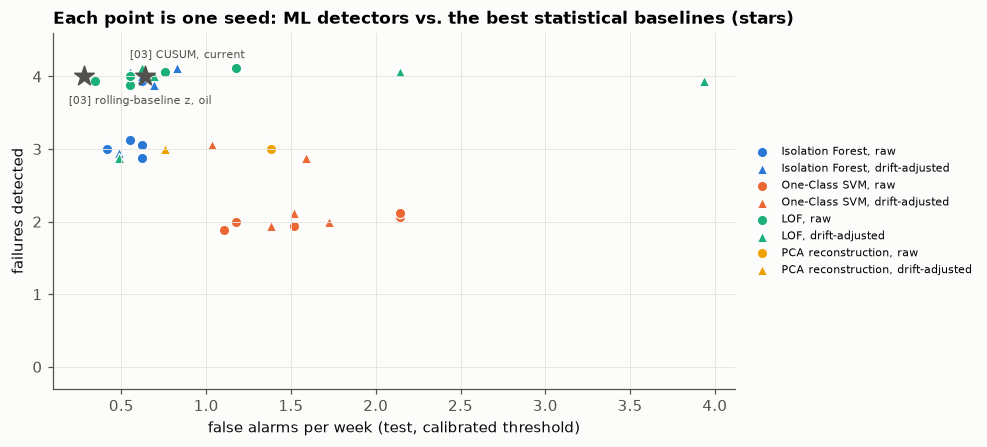

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for k, (det_name, group) in enumerate(numeric.groupby("detector", sort=False)):
    for marker, (input_name, g) in zip(["o", "^"], group.groupby("input", sort=False)):
        jitter = np.linspace(-0.12, 0.12, len(g)) if len(g) > 1 else [0]
        ax.scatter(g.false_alarms_per_week, g.detected + jitter, color=SERIES[k], marker=marker, s=46,
                   edgecolor="white", linewidth=0.8, label=f"{det_name}, {input_name}")
for name, (det, fa, dy) in {"rolling-baseline z, oil": (4, 0.28, -18), "CUSUM, current": (4, 0.64, 12)}.items():
    ax.scatter(fa, det, marker="*", s=180, color=INK_MUTED, zorder=3)
    ax.annotate(f"[03] {name}", (fa, det), xytext=(-10, dy), textcoords="offset points", fontsize=7, color=INK_MUTED)
ax.set_xlabel("false alarms per week (test, calibrated threshold)")
ax.set_ylabel("failures detected")
ax.set_yticks(range(5))
ax.set_ylim(-0.3, 4.6)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=7, frameon=False)
ax.set_title("Each point is one seed: ML detectors vs. the best statistical baselines (stars)")
fig.savefig(FIG / "04_seeds_scatter.png")
plt.show()

## 3. What the best ML detector sees

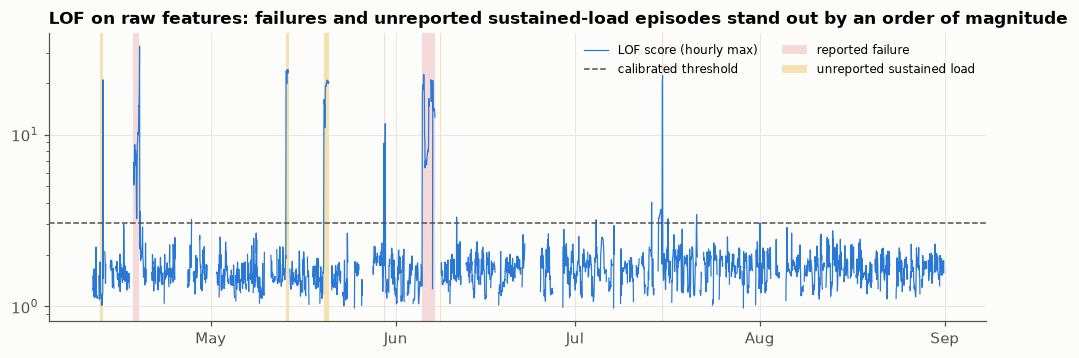

In [6]:
lof = scores["LOF, raw"]
lof_train, lof_test = ev.split(lof)
threshold = ev.calibrate(lof_train)
fig, ax = plt.subplots(figsize=(11, 3.4))
hourly = lof_test.resample("1h").max()
ax.plot(hourly.index, hourly, color=SERIES[0], lw=0.8, label="LOF score (hourly max)")
ax.axhline(threshold, color=INK_MUTED, ls="--", lw=1, label="calibrated threshold")
shade_failures(ax, FAILURES)
for i, (s, e) in enumerate(unreported[unreported.start >= ev.SPLIT][["start", "end"]].itertuples(index=False)):
    ax.axvspan(s, e, color=SERIES[3], alpha=0.3, lw=0, label="unreported sustained load" if i == 0 else None)
ax.set_yscale("log")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(loc="upper right", fontsize=8, ncol=2)
ax.set_title("LOF on raw features: failures and unreported sustained-load episodes stand out by an order of magnitude")
fig.savefig(FIG / "04_lof_score.png")
plt.show()

## 4. Explaining alarms with PCA

A score alone tells that something is wrong, not what. PCA reconstruction decomposes its error by feature: the features with the largest residuals are those that break the normal correlations. The chart shows that breakdown at the first alarm on each failure and on the false alarms.

In [7]:
pca_score, contributions = ml.pca_reconstruction(X, X_train)
pca_train, pca_test = ev.split(pca_score)
result = ev.evaluate(pca_test, ev.calibrate(pca_train))
events = result["events"]
share = contributions.div(contributions.sum(axis=1), axis=0)

def group(name):
    return name.rsplit("_", 1)[0]

rows = {}
for i, (s, e) in FAILURES[["start", "end"]].iterrows():
    hit = events[(events.label == "detection") & (events.end >= s - pd.Timedelta("12h")) & (events.start <= e)]
    if len(hit):
        t = hit.start.min()
        rows[f"failure {i}"] = share.loc[t: t + pd.Timedelta("30min")].mean()
fa = events[events.label == "false alarm"]
rows["false alarms (mean)"] = pd.concat([share.loc[s: s + pd.Timedelta("30min")] for s in fa.start]).mean()
explained = pd.DataFrame(rows).T.T.groupby(group).sum().T
explained = explained[explained.mean().sort_values(ascending=False).index]
top = explained.columns[:6]
explained = explained[top].assign(other=explained.drop(columns=top).sum(axis=1))
explained.round(2)

,reservoirs_min,load_share,current_std,tp2_mean,reservoirs_mean,load_starts,other
failure 2,0.12,0.26,0.27,0.24,0.07,0.01,0.04
failure 3,0.12,0.26,0.26,0.22,0.10,0.01,0.03
failure 4,0.29,0.12,0.03,0.09,0.32,0.10,0.05
false alarms (mean),0.42,0.15,0.12,0.12,0.14,0.03,0.03


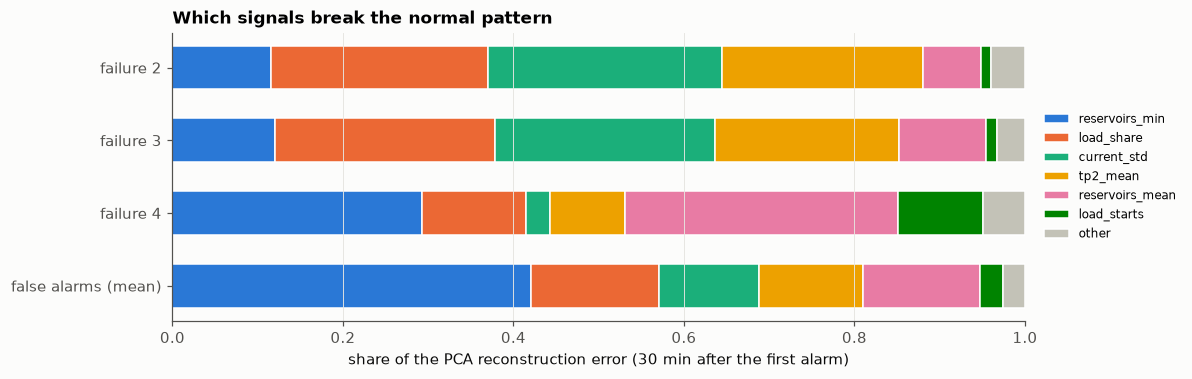

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.4))
left = np.zeros(len(explained))
for k, col in enumerate(explained.columns):
    ax.barh(explained.index, explained[col], left=left, color=SERIES[k] if col != "other" else "#c3c2b7", label=col, height=0.6,
            edgecolor="white", linewidth=1)
    left += explained[col].to_numpy()
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("share of the PCA reconstruction error (30 min after the first alarm)")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8, frameon=False)
ax.grid(axis="y", visible=False)
ax.set_title("Which signals break the normal pattern")
fig.savefig(FIG / "04_pca_explanation.png")
plt.show()

Failures 2 and 3 have the expected signature: the share of time under load, the motor current variability (cycles disappear) and the outlet pressure TP2 carry 75% of the error. Failure 4 is different, dominated by reservoir pressures, consistent with its slower onset in notebook 01. The false alarms, on the other hand, are driven by `reservoirs_min` (42%), the heavy-tailed feature that already broke the max z-score in notebook 03. PCA missed failure 1 at its calibrated threshold, so it has no bar.

The breakdown changes as a leak goes on. About two hours into failure 3, more than 90% of the error comes from the reservoir features: once the compressor has been loaded for the whole window, load share, current and outlet pressure are extreme but aligned with the main principal component, so PCA reconstructs them well, while the flat reservoir pressure (no more charge–discharge cycles) breaks the learned correlations. A reconstruction error measures *broken correlations*, not *extreme values*.

This is the practical value of a multivariate model: an alarm comes with the signals that cause it. Here the onset of a leak has a recognisable signature (load share, current variability, TP2), which helps tell it from a pressure glitch; the reservoir features, on the other hand, matter both for false alarms and for established leaks, so they cannot simply be dropped. Deciding such a change after seeing these false alarms would anyway be tuning on the test period, so the benchmark keeps all 18 features.

## 5. Verdict

| | Best classical ML (LOF, raw) | Best statistical baseline |
|---|---|---|
| Failures detected | 4/4 (all seeds) | 4/4 |
| False alarms per week | 0.55 (0.35–1.17) | 0.28 (rolling-baseline oil z) |
| Early warning on failure 4 | 12.6 h | 12.9 h (CUSUM, current) |
| Explanation of alarms | yes, with PCA | no |
| Parameters / randomness | subsample seed matters | deterministic |

On this dataset the signal is a single physical regime, *the compressor stays loaded*, that one well-chosen feature already captures. Multivariate models rediscover it but also pick up the noise of the other features. The next notebooks test methods that model time explicitly (forecast residuals, Matrix Profile, sequence autoencoders) rather than snapshots of window features.